# 02 – Datakvalitet i BRIS-uttrekkene

Oversikt over brann- og utrykningsdataene fra BRIS etter innlesing med `python -m src.bris`.
Notebooken viser kun aggregerte tall, ingen enkelthendelser.

**Tabeller i DuckDB:** `brann` (byggbranner + branner med spredning til bygg), `falske` (unødige/falske utrykninger), `kolonner` (navneoversikt).
Sensitive kolonner (adresser, merknader, risikofaktorer) er fjernet ved innlesing.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt
from src.db import query

pd.set_option("display.max_rows", 120)
pd.set_option("display.max_colwidth", 80)
plt.rcParams["figure.figsize"] = (11, 4)

## 1. Omfang

In [2]:
query('''
SELECT 'brann' AS tabell, kilde, count(*) AS rader, min(dato) AS fra, max(dato) AS til FROM brann GROUP BY kilde
UNION ALL
SELECT 'falske', kilde, count(*), min(dato), max(dato) FROM falske GROUP BY kilde
''')

,tabell,kilde,rader,fra,til
0,brann,spredning_til_bygg,460,2016-01-01,2026-09-23
1,brann,bygg,69513,2016-01-01,2026-10-18
2,falske,falske,558656,2016-01-01,2026-10-19


## 2. Hendelsestyper per år
Viktig: se etter brudd i registreringspraksis (f.eks. skorsteinsbranner).

In [3]:
per_aar = query('''
SELECT year(dato) AS aar, oppdragstype, count(*) AS n
FROM brann WHERE kilde = 'bygg'
GROUP BY ALL ORDER BY ALL
''').pivot(index="aar", columns="oppdragstype", values="n").fillna(0).astype(int)
per_aar

oppdragstype,Brann i bygning,Brann i skorstein,Brannhindrende annet i bygg,Brannhindrende tiltak komfyr
aar,,,,
2016,3011,0,0,1592
2017,3086,2,0,1775
2018,3329,4,1,1813
2019,3174,180,1047,1900
2020,2989,98,1049,1828
2021,3224,120,1425,1644
2022,3000,120,1537,1784
2023,3134,1611,1949,1725
2024,3243,1355,1898,1702


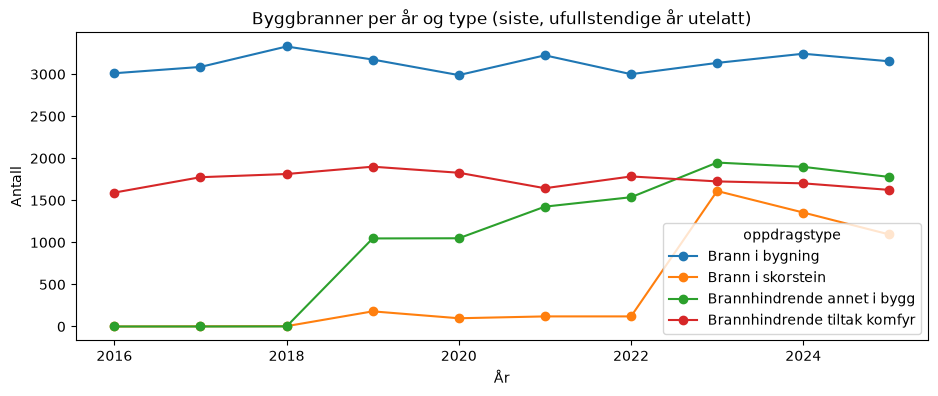

In [4]:
ax = per_aar.drop(index=per_aar.index.max()).plot(marker="o", title="Byggbranner per år og type (siste, ufullstendige år utelatt)")
ax.set_ylabel("Antall"); ax.set_xlabel("År"); plt.show()

## 3. Sesong: branner vs. falske utrykninger
Andel av hendelsene som faller i hver måned (normalisert, så kurvene kan sammenlignes).

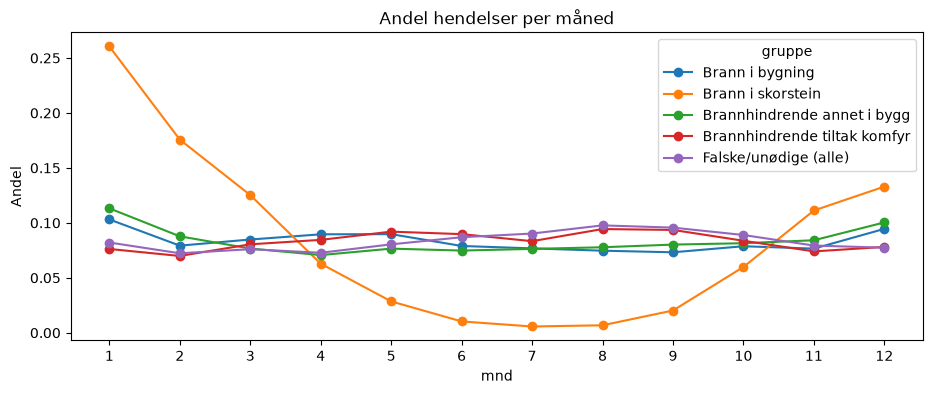

In [5]:
sesong = query('''
SELECT month(dato) AS mnd, oppdragstype AS gruppe, count(*) AS n FROM brann WHERE kilde='bygg' GROUP BY ALL
UNION ALL
SELECT month(dato), 'Falske/unødige (alle)', count(*) FROM falske GROUP BY ALL
''').pivot(index="mnd", columns="gruppe", values="n")
andel = sesong / sesong.sum()
ax = andel.plot(marker="o", title="Andel hendelser per måned")
ax.set_ylabel("Andel"); ax.set_xticks(range(1, 13)); plt.show()

## 4. Tid på døgnet

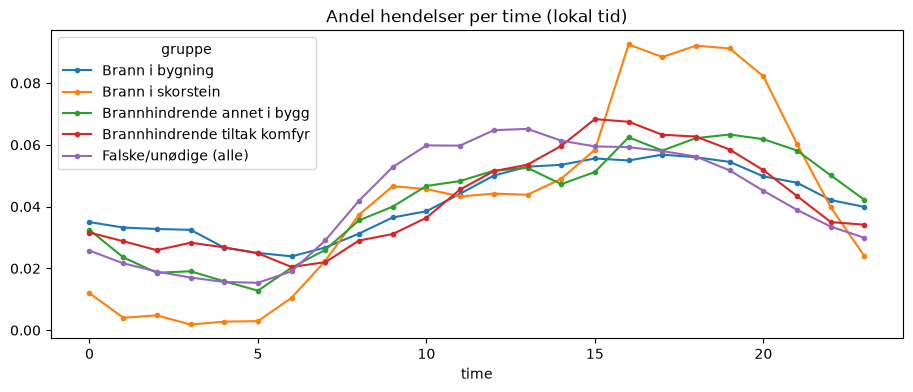

In [6]:
tod = query('''
SELECT hour(tidspunkt) AS time, oppdragstype AS gruppe, count(*) AS n FROM brann WHERE kilde='bygg' GROUP BY ALL
UNION ALL
SELECT hour(tidspunkt), 'Falske/unødige (alle)', count(*) FROM falske GROUP BY ALL
''').pivot(index="time", columns="gruppe", values="n")
(tod / tod.sum()).plot(marker=".", title="Andel hendelser per time (lokal tid)"); plt.show()

## 5. Geografi

In [7]:
query('''
SELECT fylke, count(*) AS branner,
       (SELECT count(*) FROM falske f WHERE f.fylke = b.fylke) AS falske
FROM brann b GROUP BY fylke ORDER BY branner DESC
''')

,fylke,branner,falske
0,Oslo,10319,97791
1,Akershus,7379,81312
2,Trøndelag,7307,39074
3,Vestland,7219,39880
4,Innlandet,5779,32178
5,Agder,4812,43982
6,Rogaland,4702,46098
7,Østfold,3824,26205
8,Buskerud,3632,29775
9,Vestfold,3592,31962


In [8]:
# Koordinater: mangler eller utenfor et grovt rektangel rundt Norge (inkl. Svalbard)
query('''
SELECT 'brann' AS tabell,
       count(*) FILTER (WHERE lat IS NULL OR lon IS NULL) AS mangler_koordinater,
       count(*) FILTER (WHERE lat NOT BETWEEN 57.5 AND 81 OR lon NOT BETWEEN 4 AND 32) AS utenfor_norge
FROM brann
UNION ALL
SELECT 'falske',
       count(*) FILTER (WHERE lat IS NULL OR lon IS NULL),
       count(*) FILTER (WHERE lat NOT BETWEEN 57.5 AND 81 OR lon NOT BETWEEN 4 AND 32)
FROM falske
''')

,tabell,mangler_koordinater,utenfor_norge
0,brann,3,67
1,falske,7,1660


In [ ]:
pts = query("SELECT lon, lat FROM brann WHERE lat BETWEEN 57.5 AND 72 AND lon BETWEEN 4 AND 32")
fig, ax = plt.subplots(figsize=(6, 8))
ax.scatter(pts.lon, pts.lat, s=0.3, alpha=0.3)
ax.set_title("Brannhendelser (fastlandet)"); ax.set_aspect(2); plt.show()

## 6. Utfyllingsgrad per kolonne (brann, kilde = bygg)
Andel rader der feltet har en verdi. Lav utfylling betyr at feltet er lite egnet som variabel.

In [10]:
cols = query("SELECT column_name FROM information_schema.columns WHERE table_name='brann'").column_name
expr = ", ".join(f'avg(("{c}" IS NOT NULL)::int) AS "{c}"' for c in cols)
fill = query(f"SELECT {expr} FROM brann WHERE kilde='bygg'").T.rename(columns={0: "utfylt"})
fill.sort_values("utfylt").style.format("{:.0%}")

,utfylt
spredning_til__naeringsbygg,0%
hvilken_type_brann_var_den_opprinnelige_brannen,0%
spredning_til__ingen_spredning,0%
spredning_til__enebolig,0%
spredning_til__annen_bolig,0%
spredning_til__garasje_eller_annet_bygg,0%
spredning_til__skog_eller_annen_utmark,0%
stasjoner,0%
spredning_til__gress_eller_annen_innmark,0%
spredning_til__tunell,0%


## 7. Endringer i kodeverk over tid (falske utrykninger)
Kategorier merket «(utgått)» viser at BRIS har endret klassifiseringen.

In [11]:
kode = query('''
SELECT year(dato) AS aar,
       count(*) FILTER (WHERE oppdragstype LIKE '%(utgått)%') AS utgatte_koder,
       count(*) AS totalt
FROM falske GROUP BY aar ORDER BY aar
''')
kode["andel_utgatt"] = (kode.utgatte_koder / kode.totalt).round(3)
kode

,aar,utgatte_koder,totalt,andel_utgatt
0,2016,43066,47923,0.899
1,2017,43462,49176,0.884
2,2018,44459,52785,0.842
3,2019,46690,53673,0.870
4,2020,40960,47087,0.870
5,2021,44192,50405,0.877
6,2022,48499,54469,0.890
7,2023,179,55199,0.003
8,2024,0,56209,0.000
9,2025,0,51938,0.000


## 8. Innsatsvarighet

In [12]:
query('''
SELECT oppdragstype, count(innsatsvarighet_s) AS n,
       round(median(innsatsvarighet_s)/60, 1) AS median_min,
       round(quantile_cont(innsatsvarighet_s, 0.9)/60, 1) AS p90_min
FROM brann GROUP BY oppdragstype ORDER BY n DESC
''')

,oppdragstype,n,median_min,p90_min
0,Brann i bygning,31476,66.4,379.8
1,Brannhindrende tiltak komfyr,17109,18.4,50.0
2,Brannhindrende annet i bygg,10952,21.6,68.2
3,Brann i skorstein,5068,41.8,103.3
4,Brann i personbil,88,70.3,246.9
5,Brann i gress- eller innmark,88,79.8,237.4
6,Brann annet,80,37.6,160.6
7,Brann i campingvogn/telt,22,78.2,274.6
8,Brann i skog- eller utmark,21,291.7,1484.3
9,Brann i annet kjøretøy,21,53.3,126.5


## 9. Funn og ting å følge opp (per 9. nov. 2026)
- **«Brann i bygning» er stabil**, rundt 3000–3300 per år for 2016–2025. Den passer godt som hovedvariabel.
- **«Brann i skorstein»** er nesten ikke registrert før 2019, og øker fra rundt 120 til rundt 1600 per år i 2023. Det er et brudd i registreringen, ikke en reell endring. Analyser derfor helst 2023→ for skorstein, eller ta med en variabel for periode.
- **«Brannhindrende annet i bygg»** registreres først fra 2019.
- **«Brannhindrende tiltak komfyr»** er stabil (rundt 1600–1900 per år), men er trolig ikke en faktisk brann. Det må avklares med veileder.
- **Falske utrykninger** fikk nytt kodeverk i 2023. Rundt 85–90 % av hendelsene før 2023 har koder som nå er «(utgått)». Kategoriene må samordnes før de kan sammenlignes over tid.
- Koordinater: 3 branner mangler, og 67 ligger utenfor grovrektangelet rundt Norge. De må sjekkes eller fjernes.
- Utendørsbranner (gress, skog, kjøretøy) mangler i uttrekket, bortsett fra de som spredte seg til bygg.